# Reverse engineering `spike_data.npz`

The file holds one 10 second voltage-like trace (`raw_data`) sampled at 1 kHz (`t`). The goal is to figure out the process that generated it, write that process down as a model, and show that the model can produce data that is statistically indistinguishable from the real trace.

**The recovered generative model** (three parts: drift, spikes, noise)

$$x(t) = D\,\sin(2\pi f t + \varphi) + \sum_{k} A\, e^{-(t - t_k)/\tau}\, H(t - t_k) + \varepsilon(t)$$

where

* $t_k$ are spike times from a homogeneous Poisson process with rate $\lambda$
* $A\, e^{-(t - t_k)/\tau}\, H(t - t_k)$ is the spike shape: an instant jump of height $A$ that decays exponentially with time constant $\tau$ ($H$ is the Heaviside step, so the spike is zero before $t_k$)
* $D\,\sin(2\pi f t + \varphi)$ is a slow baseline drift with amplitude $D$, frequency $f$ and phase $\varphi$
* $\varepsilon(t) \sim \mathcal{N}(0, \sigma^2)$ is independent (white) Gaussian noise at every sample

The notebook walks through how each piece was found, in the order I found it.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats, optimize

d = np.load("spike_data.npz")
t = d["t"]
x = d["raw_data"]
n = len(x)
dt = t[1] - t[0]
print(f"{n} samples, dt = {dt*1000:.1f} ms, duration = {t[-1]+dt:.1f} s")
print(f"mean = {x.mean():.3f}, std = {x.std():.3f}, min = {x.min():.2f}, max = {x.max():.2f}")

10000 samples, dt = 1.0 ms, duration = 10.0 s
mean = 0.077, std = 0.734, min = -1.69, max = 6.20


## 1. Look at the raw trace

Before fitting anything, plot it. Three things jump out: (1) tall, sharp upward events (the spikes), (2) a small amount of fast noise around them, and (3) the baseline slowly wanders up and then down over the 10 seconds.

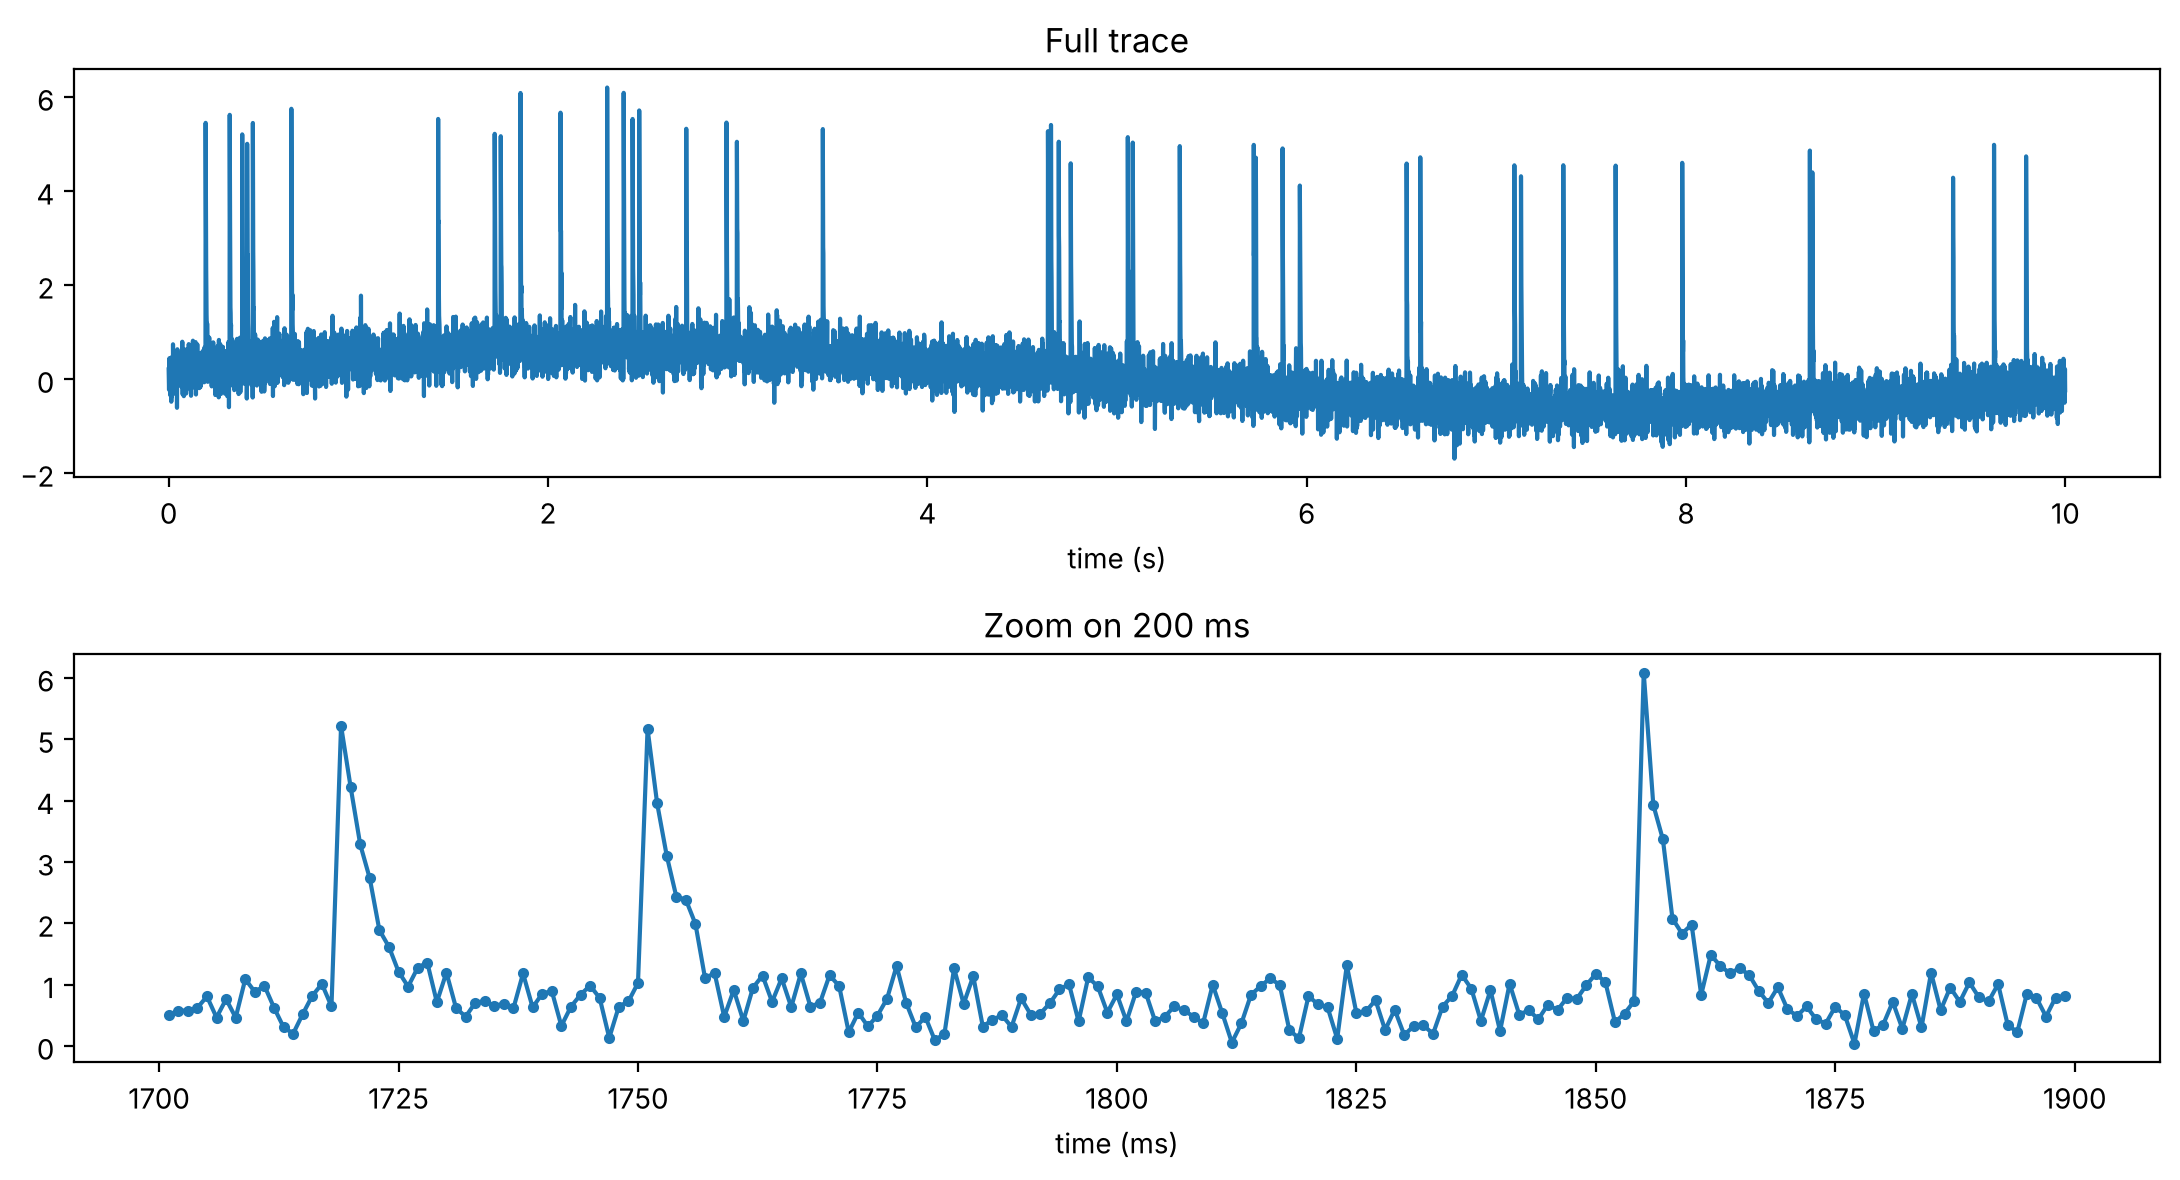

In [2]:
fig, ax = plt.subplots(2, 1, figsize=(11, 6))
ax[0].plot(t, x)
ax[0].set_title("Full trace")
ax[0].set_xlabel("time (s)")
zoom = (t > 1.7) & (t < 1.9)
ax[1].plot(t[zoom] * 1000, x[zoom], marker=".")
ax[1].set_title("Zoom on 200 ms")
ax[1].set_xlabel("time (ms)")
plt.tight_layout()
plt.show()

## 2. Find the spikes

The obvious approach is a threshold (for example, mark every time $x(t)$ crosses 2). That gives 45 events, but a few of them are fake: the decaying tail of a real spike can dip below 2 and come back above it because of noise, which counts the same spike twice.

Looking at the zoom, every spike starts with a jump of about 5 units in a **single** sample. So a cleaner detector is the first difference $\Delta x[i] = x[i] - x[i-1]$. Noise alone makes $\Delta x$ swing by roughly $\sqrt{2}\,\sigma \approx 0.4$, while a spike onset makes it jump by about 5, so a cutoff of 2.5 separates them with a huge margin. I use a plain threshold on $\Delta x$ rather than a peak finder so that two spikes in back-to-back samples are both caught (the second one still adds a jump of about 3.6).

42 spikes detected
jump sizes: [4.14 4.17 4.29 4.32 4.42 4.48 4.56 4.57 4.61 4.67 4.78 4.8  4.82 4.89
 4.91 4.97 5.   5.02 5.05 5.11 5.11 5.11 5.13 5.13 5.18 5.2  5.2  5.26
 5.36 5.36 5.36 5.37 5.4  5.4  5.41 5.44 5.49 5.6  5.77 5.79 5.84 5.88]


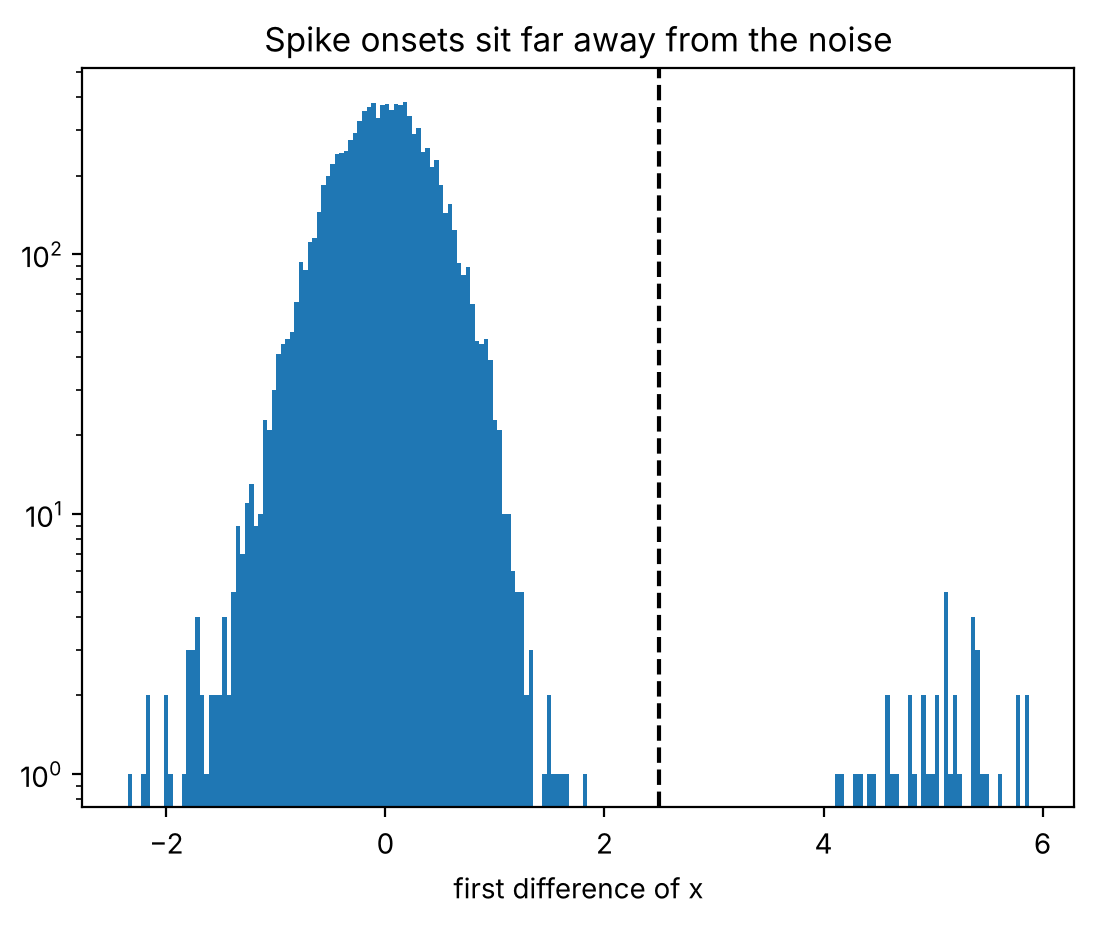

In [3]:
dx = np.diff(x, prepend=x[0])
onsets = np.flatnonzero(dx > 2.5)
t_k = t[onsets]
print(f"{len(onsets)} spikes detected")
print("jump sizes:", np.round(np.sort(dx[onsets]), 2))

plt.hist(dx, bins=200)
plt.yscale("log")
plt.axvline(2.5, color="k", linestyle="--")
plt.xlabel("first difference of x")
plt.title("Spike onsets sit far away from the noise")
plt.show()

## 3. Learn the spike shape without assuming one

I did not want to guess the waveform, so I estimated it non-parametrically. Treat the trace as a constant plus the same unknown kernel $h[\ell]$ (for lags $\ell = 0, \dots, 39$ ms) added at every spike onset:

$$x[i] = \sum_k h[i - i_k] + \text{noise}$$

This is linear in $h[\ell]$, so ordinary least squares solves it directly, and it handles overlapping spikes automatically.

The estimated kernel jumps to about 5 and then shrinks by roughly the same fraction every millisecond. A constant ratio per step is the signature of an exponential decay, and on a log scale it is a straight line.

h[0..9] = [5.082 3.613 2.617 1.982 1.281 1.023 0.713 0.532 0.404 0.355]
ratio h[l+1]/h[l] = [0.711 0.724 0.757 0.646 0.798 0.697 0.746]


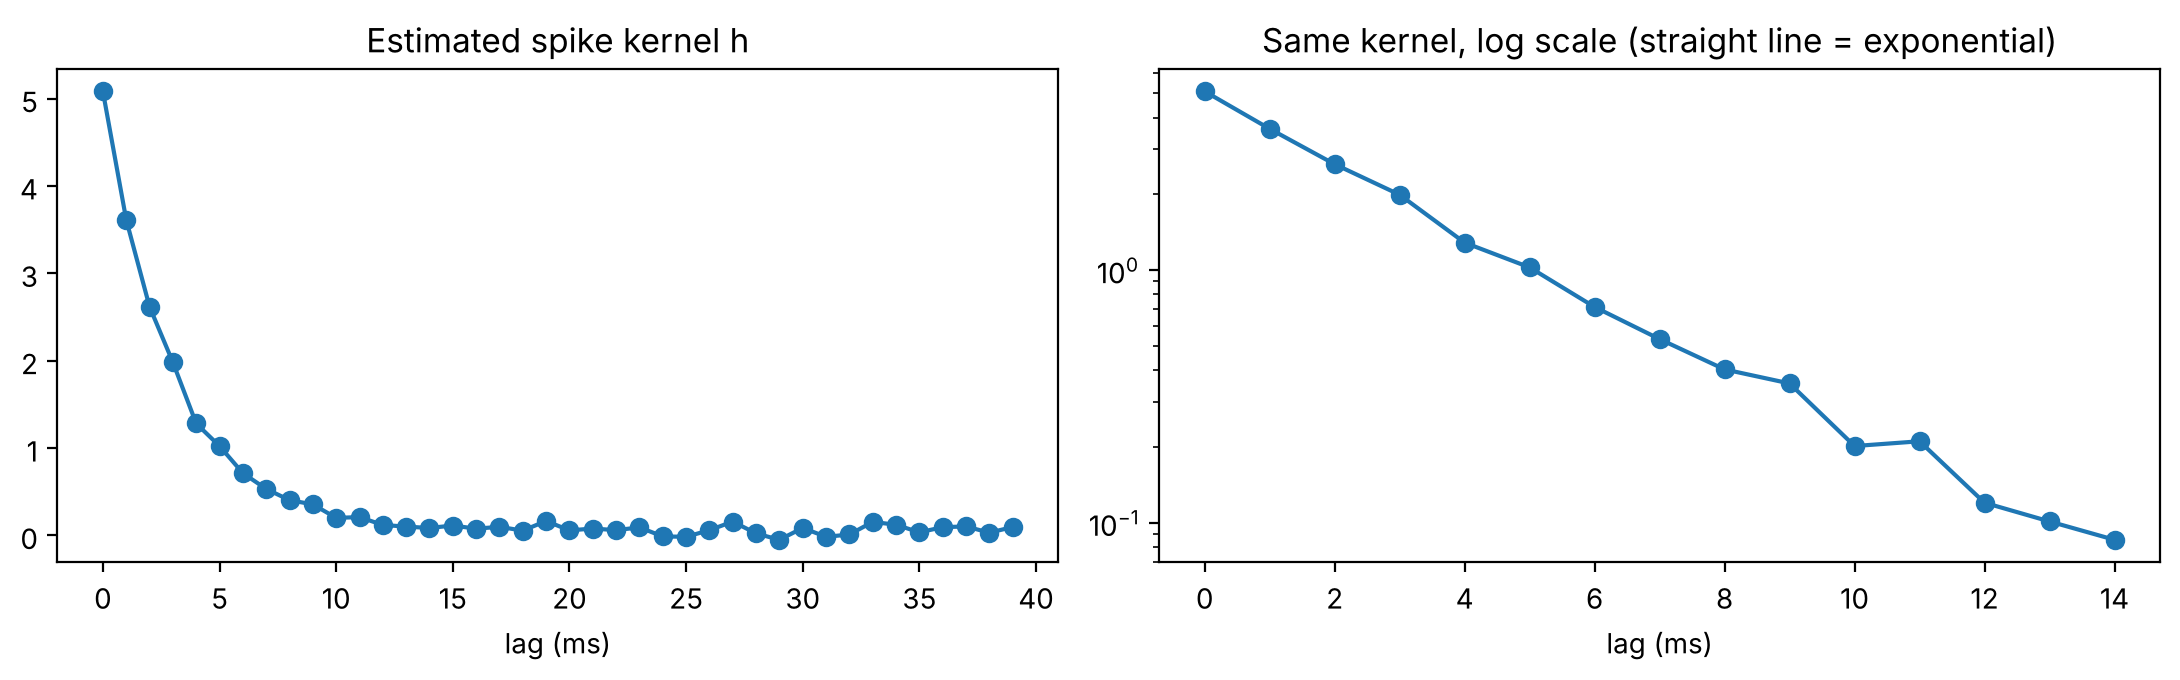

lag-1 to lag-5 autocorrelation of what is left: [0.715 0.72  0.715 0.726 0.723]


In [4]:
L = 40
X = np.zeros((n, L))
for s in onsets:
    for lag in range(L):
        if s + lag < n:
            X[s + lag, lag] += 1
design = X
coef, *_ = np.linalg.lstsq(design, x, rcond=None)
h = coef
print("h[0..9] =", np.round(h[:10], 3))
print("ratio h[l+1]/h[l] =", np.round(h[1:8] / h[:7], 3))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(np.arange(L), h, marker="o")
ax[0].set_xlabel("lag (ms)")
ax[0].set_title("Estimated spike kernel h")
ax[1].semilogy(np.arange(15), h[:15], marker="o")
ax[1].set_xlabel("lag (ms)")
ax[1].set_title("Same kernel, log scale (straight line = exponential)")
plt.tight_layout()
plt.show()

resid0 = x - design @ coef
print("lag-1 to lag-5 autocorrelation of what is left:",
      np.round([np.corrcoef(resid0[:-k], resid0[k:])[0, 1] for k in range(1, 6)], 3))

The tail of $h$ also does not quite reach zero (it hovers around 0.1), and the residual left over after removing spikes has an autocorrelation of about 0.72 at **every** lag from 1 to 5 ms. White noise would have autocorrelation near 0. A flat, high autocorrelation means there is a slow component still in the data: the baseline drift visible in the first plot.

## 4. Characterise the slow drift

Smoothing the spike-free trace shows the baseline rising to a peak near $t = 2.5$ s, falling to a trough near $t = 7.5$ s, and coming back up by $t = 10$ s. That is close to one full cycle of a sine wave with a period of about 10 s.

I compared several candidate drift shapes using the Bayesian Information Criterion, $\text{BIC} = n \ln(\text{RSS}/n) + k \ln n$, where lower is better and $k$ is the number of parameters (so extra parameters get penalised).

no drift                     k=0  BIC= -11451.5  rmse=0.5641
linear                       k=2  BIC= -19273.7  rmse=0.3811
cubic polynomial             k=4  BIC= -24035.6  rmse=0.3001
quintic polynomial           k=6  BIC= -24130.5  rmse=0.2984
sine, f fixed at 0.1 Hz      k=2  BIC= -23544.1  rmse=0.3079


sine, f free                 k=3  BIC= -24155.6  rmse=0.2984


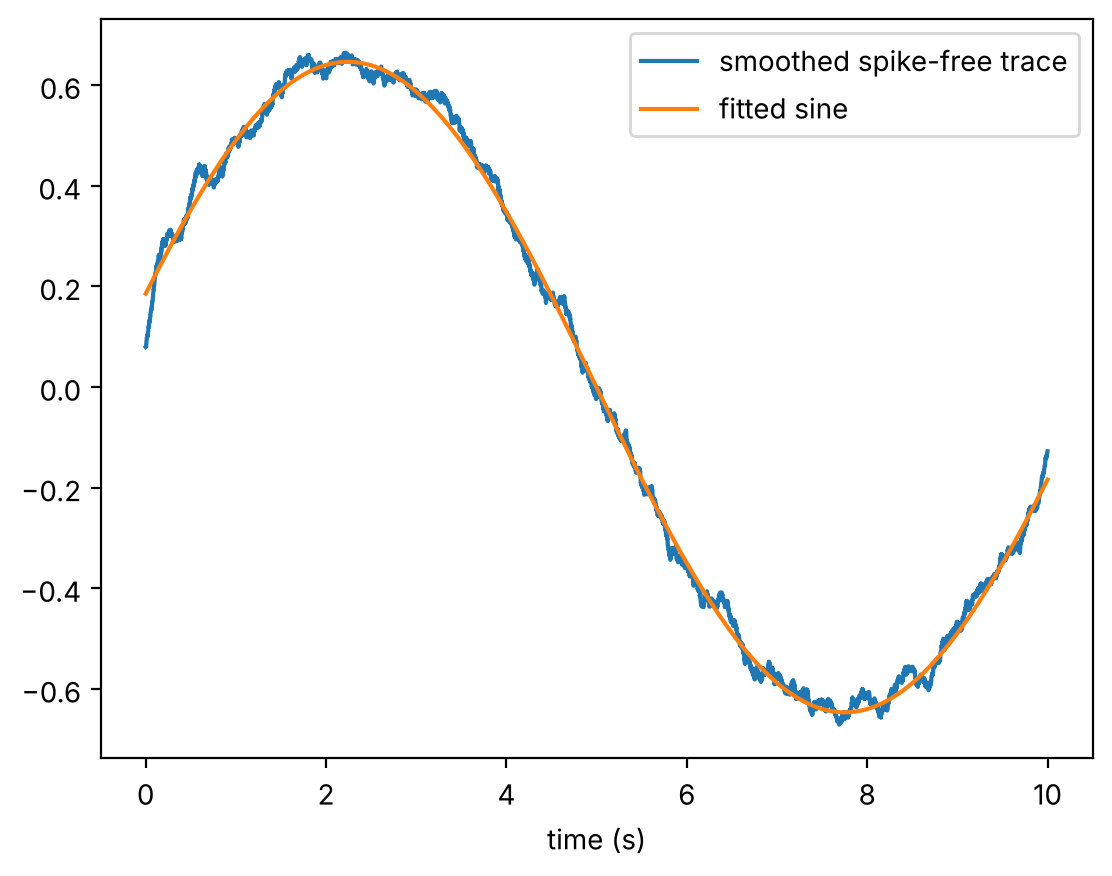

In [5]:
def exp_spikes(onsets, A, tau):
    # sum of A * exp(-(t - t_k)/tau) * H(t - t_k) over all spikes
    y = np.zeros(n)
    amps = np.broadcast_to(A, len(onsets))
    for s, a in zip(onsets, amps):
        y[s:] += a * np.exp(-(t[s:] - t[s]) / tau)
    return y

y_nospike = x - exp_spikes(onsets, 5.0, 0.003)   # rough spike removal, refined later

def bic(rss, k):
    return n * np.log(rss / n) + k * np.log(n)

def sincos(f):
    return np.column_stack([np.sin(2 * np.pi * f * t), np.cos(2 * np.pi * f * t)])

candidates = {
    "linear": np.column_stack([np.ones(n), t]),
    "cubic polynomial": np.vander(t, 4),
    "quintic polynomial": np.vander(t, 6),
    "sine, f fixed at 0.1 Hz": sincos(0.1),
}
print(f"{'no drift':28s} k=0  BIC={bic((y_nospike**2).sum(), 0):9.1f}  rmse={np.sqrt((y_nospike**2).mean()):.4f}")
for name, M in candidates.items():
    c, *_ = np.linalg.lstsq(M, y_nospike, rcond=None)
    rss = ((y_nospike - M @ c) ** 2).sum()
    print(f"{name:28s} k={M.shape[1]}  BIC={bic(rss, M.shape[1]):9.1f}  rmse={np.sqrt(rss/n):.4f}")

sine = lambda q: q[0] * np.sin(2 * np.pi * q[1] * t + q[2])
q = optimize.least_squares(lambda q: sine(q) - y_nospike, [0.6, 0.1, 0]).x
rss = ((y_nospike - sine(q)) ** 2).sum()
print(f"{'sine, f free':28s} k=3  BIC={bic(rss, 3):9.1f}  rmse={np.sqrt(rss/n):.4f}")

plt.plot(t, np.convolve(y_nospike, np.ones(201) / 201, "same"), label="smoothed spike-free trace")
plt.plot(t, sine(q), label="fitted sine")
plt.xlabel("time (s)")
plt.legend()
plt.show()

A sine with its frequency left free has the lowest (best) BIC, beating every polynomial even though it uses fewer parameters. Once it is removed the rmse drops to about 0.30 and stops improving, which is the noise floor.

## 5. Fit everything at once

Now that every piece has a form, fit all of them jointly with nonlinear least squares, so that the drift estimate does not get biased by spike tails and vice versa. The parameters are $D, f, \varphi, A, \tau$. Standard errors come from the Jacobian at the solution: $\operatorname{Cov}(\hat\theta) \approx \hat\sigma^2 (J^\top J)^{-1}$.

In [6]:
def full_model(p, onsets):
    D, f, phi, A, tau = p
    return D * np.sin(2 * np.pi * f * t + phi) + exp_spikes(onsets, A, tau)

def fit(x, onsets):
    p0 = [0.6, 0.1, 0, 5, 0.003]
    res = optimize.least_squares(lambda p: full_model(p, onsets) - x, p0,
                                 x_scale=[0.1, 0.01, 0.1, 1, 0.001])
    r = x - full_model(res.x, onsets)
    cov = np.linalg.inv(res.jac.T @ res.jac) * r.var()
    return res.x, np.sqrt(np.diag(cov)), r

p_hat, se, resid = fit(x, onsets)
names = ["D (drift amplitude)", "f (drift freq, Hz)", "phi (drift phase, rad)",
         "A (spike height)", "tau (decay, ms)"]
scale = [1, 1, 1, 1, 1000]   # show tau in ms
for nm, v, e, s in zip(names, p_hat, se, scale):
    print(f"{nm:24s} {v*s: .4f}  +/- {e*s:.4f}")
sigma_hat = resid.std()
lam_hat = len(onsets) / (t[-1] + dt)
print(f"{'sigma (noise sd)':24s} {sigma_hat: .4f}")
print(f"{'lambda (spike rate, Hz)':24s} {lam_hat: .2f}")

D (drift amplitude)       0.6466  +/- 0.0042
f (drift freq, Hz)        0.0908  +/- 0.0004
phi (drift phase, rad)    0.2912  +/- 0.0143
A (spike height)          5.0177  +/- 0.0397
tau (decay, ms)           2.9892  +/- 0.0390
sigma (noise sd)          0.2984
lambda (spike rate, Hz)   4.20


**Is the spike height the same for every spike?** I refit each spike with its own amplitude $A_k$ (with $\tau$ and the drift held fixed) and compared the spread of the $A_k$ to the spread you would expect from noise alone. A chi-square test does not reject equal heights, so one shared $A$ is enough.

In [7]:
D, f, phi, A, tau = p_hat
baseline = D * np.sin(2 * np.pi * f * t + phi)
K = np.zeros((n, len(onsets)))
for j, s in enumerate(onsets):
    K[s:, j] = np.exp(-(t[s:] - t[s]) / tau)
A_k, *_ = np.linalg.lstsq(K, x - baseline, rcond=None)
se_k = np.sqrt(np.diag(np.linalg.inv(K.T @ K))) * sigma_hat
chi2 = (((A_k - A_k.mean()) / se_k) ** 2).sum()
print(f"A_k: mean {A_k.mean():.3f}, sd {A_k.std(ddof=1):.3f}; sd expected from noise alone {se_k.mean():.3f}")
print(f"chi-square test of equal heights: p = {stats.chi2.sf(chi2, len(onsets) - 1):.2f}")

A_k: mean 5.018, sd 0.204; sd expected from noise alone 0.208
chi-square test of equal heights: p = 0.55


## 6. Check the noise

If the model is right, the residual $r(t) = x(t) - \hat{x}(t)$ should be pure noise: Gaussian, mean zero, and uncorrelated from one sample to the next.

residual mean 0.0029, sd 0.2984, skew 0.020, excess kurtosis -0.045
normality (D'Agostino) p = 0.487


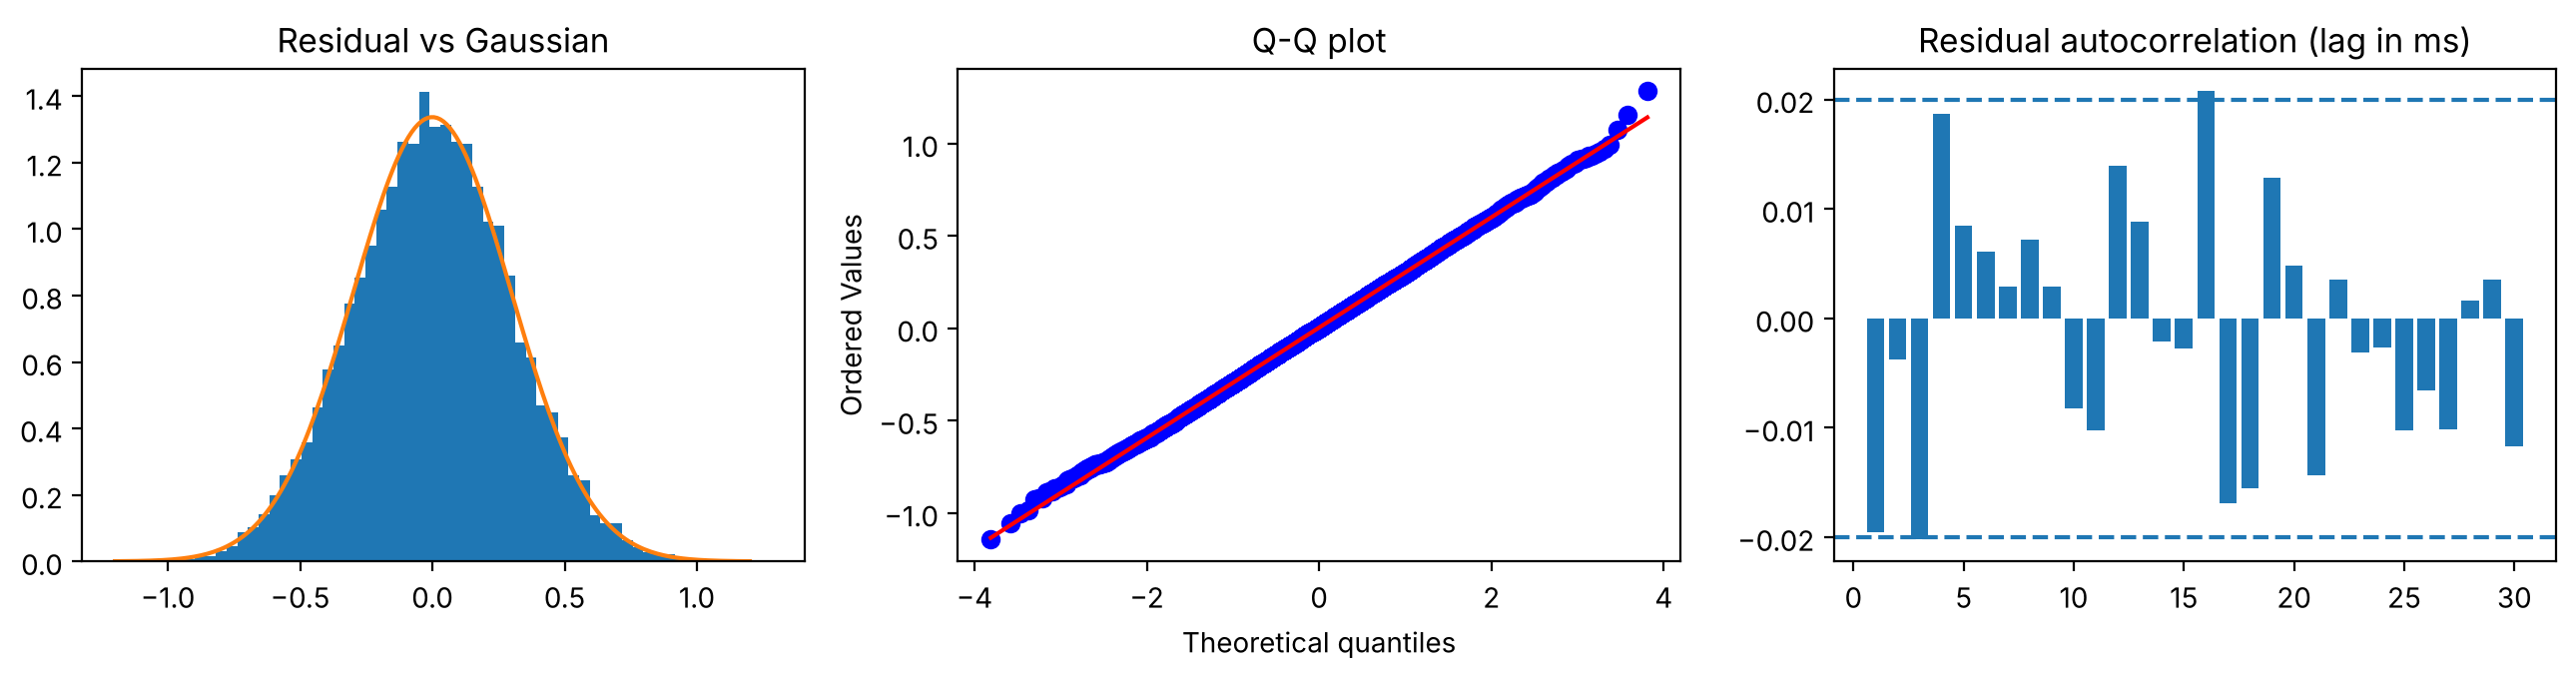

In [8]:
print(f"residual mean {resid.mean():.4f}, sd {resid.std():.4f}, "
      f"skew {stats.skew(resid):.3f}, excess kurtosis {stats.kurtosis(resid):.3f}")
print("normality (D'Agostino) p =", round(stats.normaltest(resid).pvalue, 3))
acf = [np.corrcoef(resid[:-k], resid[k:])[0, 1] for k in range(1, 31)]

fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
ax[0].hist(resid, bins=60, density=True)
g = np.linspace(-1.2, 1.2, 200)
ax[0].plot(g, stats.norm.pdf(g, 0, sigma_hat))
ax[0].set_title("Residual vs Gaussian")
stats.probplot(resid, plot=ax[1])
ax[1].set_title("Q-Q plot")
ax[2].bar(range(1, 31), acf)
ax[2].axhline(2 / np.sqrt(n), linestyle="--")
ax[2].axhline(-2 / np.sqrt(n), linestyle="--")
ax[2].set_title("Residual autocorrelation (lag in ms)")
plt.tight_layout()
plt.show()

Skew and excess kurtosis are both about 0, the normality test passes, and the autocorrelations sit inside the $\pm 2/\sqrt{n}$ band. Compare that with step 3, where the residual autocorrelation was 0.72. So the noise is white Gaussian with $\sigma \approx 0.30$.

## 7. Check the spike timing

The last piece is *when* spikes happen. The simplest candidate is a homogeneous Poisson process, which makes three testable predictions:

1. interspike intervals (ISIs) follow an exponential distribution with rate $\lambda$, so their coefficient of variation (CV) is about 1
2. spike times are spread uniformly over the recording
3. spike counts in equal windows have Fano factor (variance / mean) about 1

I also checked whether spiking is tied to the drift (for example, more spikes when the baseline is high) with a Poisson regression of spike probability on $\sin(2\pi f t + \varphi)$.

rate = 4.20 Hz (95% CI 3.0 to 5.5 Hz)
ISI CV = 1.09, shortest ISI = 11 ms
KS test, ISIs vs exponential: p = 0.72
KS test, spike times vs uniform: p = 0.45
counts per second [6 4 8 1 4 7 2 5 2 3], Fano factor = 1.26
does drift modulate spiking? likelihood-ratio p = 0.37


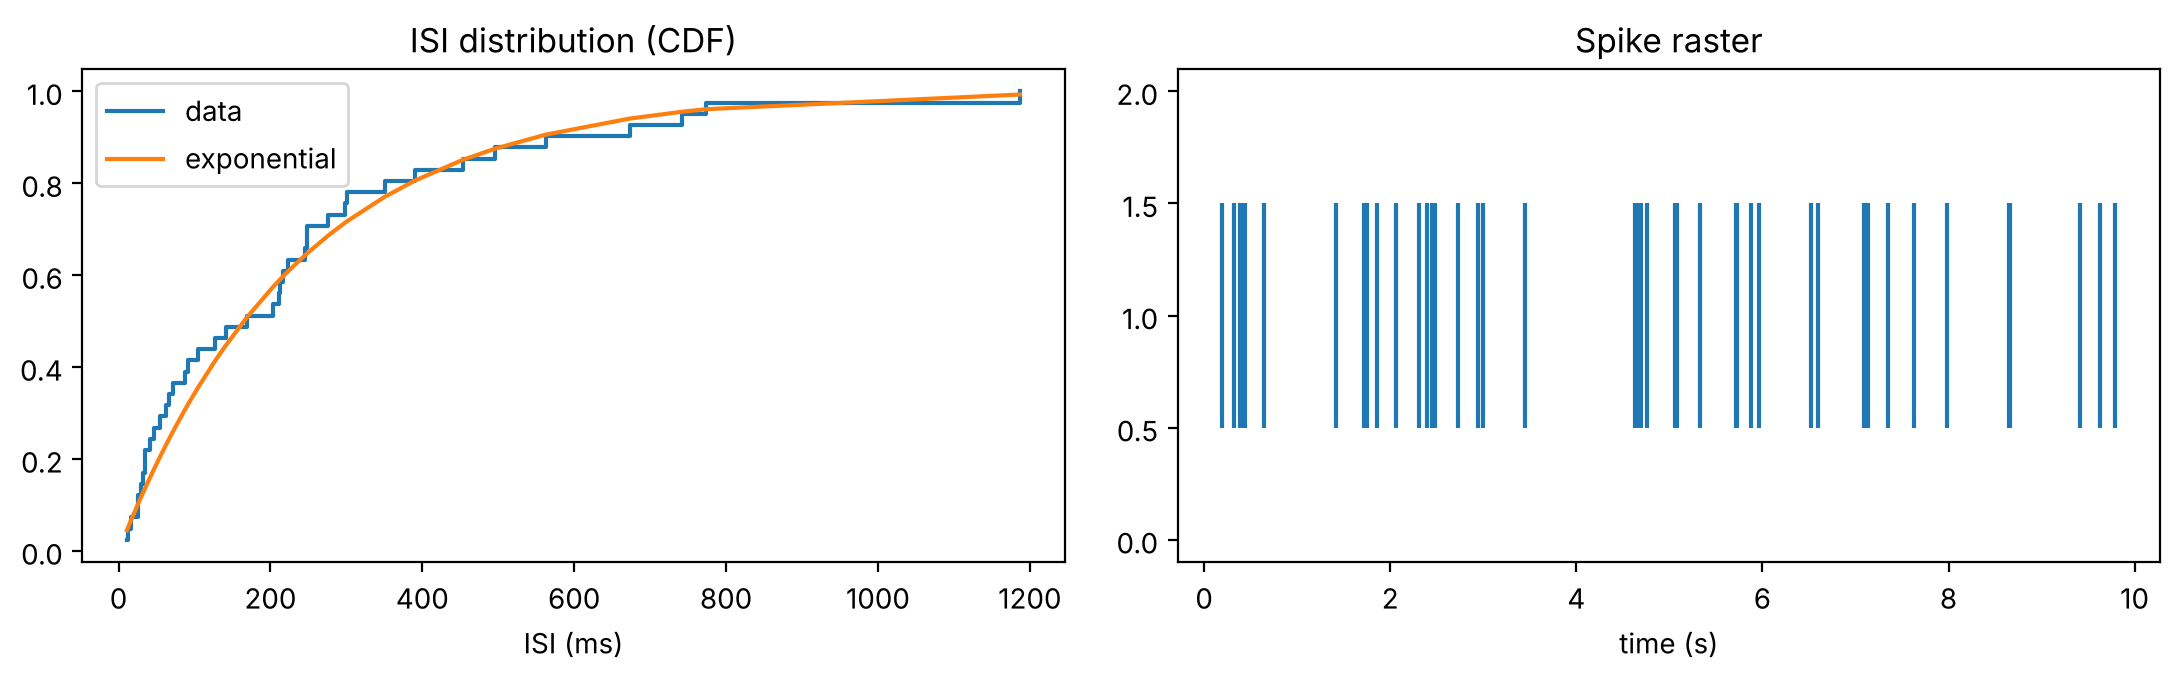

In [9]:
T = t[-1] + dt
isi = np.diff(t_k)
lo, hi = stats.poisson.interval(0.95, len(onsets))
print(f"rate = {lam_hat:.2f} Hz (95% CI {lo/T:.1f} to {hi/T:.1f} Hz)")
print(f"ISI CV = {isi.std(ddof=1)/isi.mean():.2f}, shortest ISI = {isi.min()*1000:.0f} ms")
print(f"KS test, ISIs vs exponential: p = {stats.kstest(isi, 'expon', args=(0, 1/lam_hat)).pvalue:.2f}")
print(f"KS test, spike times vs uniform: p = {stats.kstest(t_k / T, 'uniform').pvalue:.2f}")
counts = np.histogram(t_k, np.arange(0, T + 1e-9, 1))[0]
print(f"counts per second {counts}, Fano factor = {counts.var(ddof=1)/counts.mean():.2f}")

spk = np.zeros(n); spk[onsets] = 1
drift = np.sin(2 * np.pi * f * t + phi)
Xg = np.column_stack([np.ones(n), drift])
nll = lambda beta: -(spk * (Xg @ beta) - np.exp(Xg @ beta) * dt).sum()
full = optimize.minimize(nll, [np.log(lam_hat), 0])
null = optimize.minimize(lambda b0: nll([b0[0], 0]), [np.log(lam_hat)])
print(f"does drift modulate spiking? likelihood-ratio p = {stats.chi2.sf(2*(null.fun - full.fun), 1):.2f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
s_isi = np.sort(isi)
ax[0].step(s_isi * 1000, np.arange(1, len(isi) + 1) / len(isi), where="post", label="data")
ax[0].plot(s_isi * 1000, 1 - np.exp(-lam_hat * s_isi), label="exponential")
ax[0].set_xlabel("ISI (ms)")
ax[0].set_title("ISI distribution (CDF)")
ax[0].legend()
ax[1].eventplot(t_k)
ax[1].set_xlabel("time (s)")
ax[1].set_title("Spike raster")
plt.tight_layout()
plt.show()

Every test is consistent with a homogeneous Poisson process at about 4.2 Hz, and the drift has no detectable effect on spike timing (the drift is just added to the voltage, it does not drive the spikes).

## 8. The model as a generator

Putting the pieces together, here is a function that produces new data from the recovered model.

D      = 0.6466
f      = 0.09079
phi    = 0.2912
A      = 5.018
tau    = 0.002989
sigma  = 0.2984
rate   = 4.2


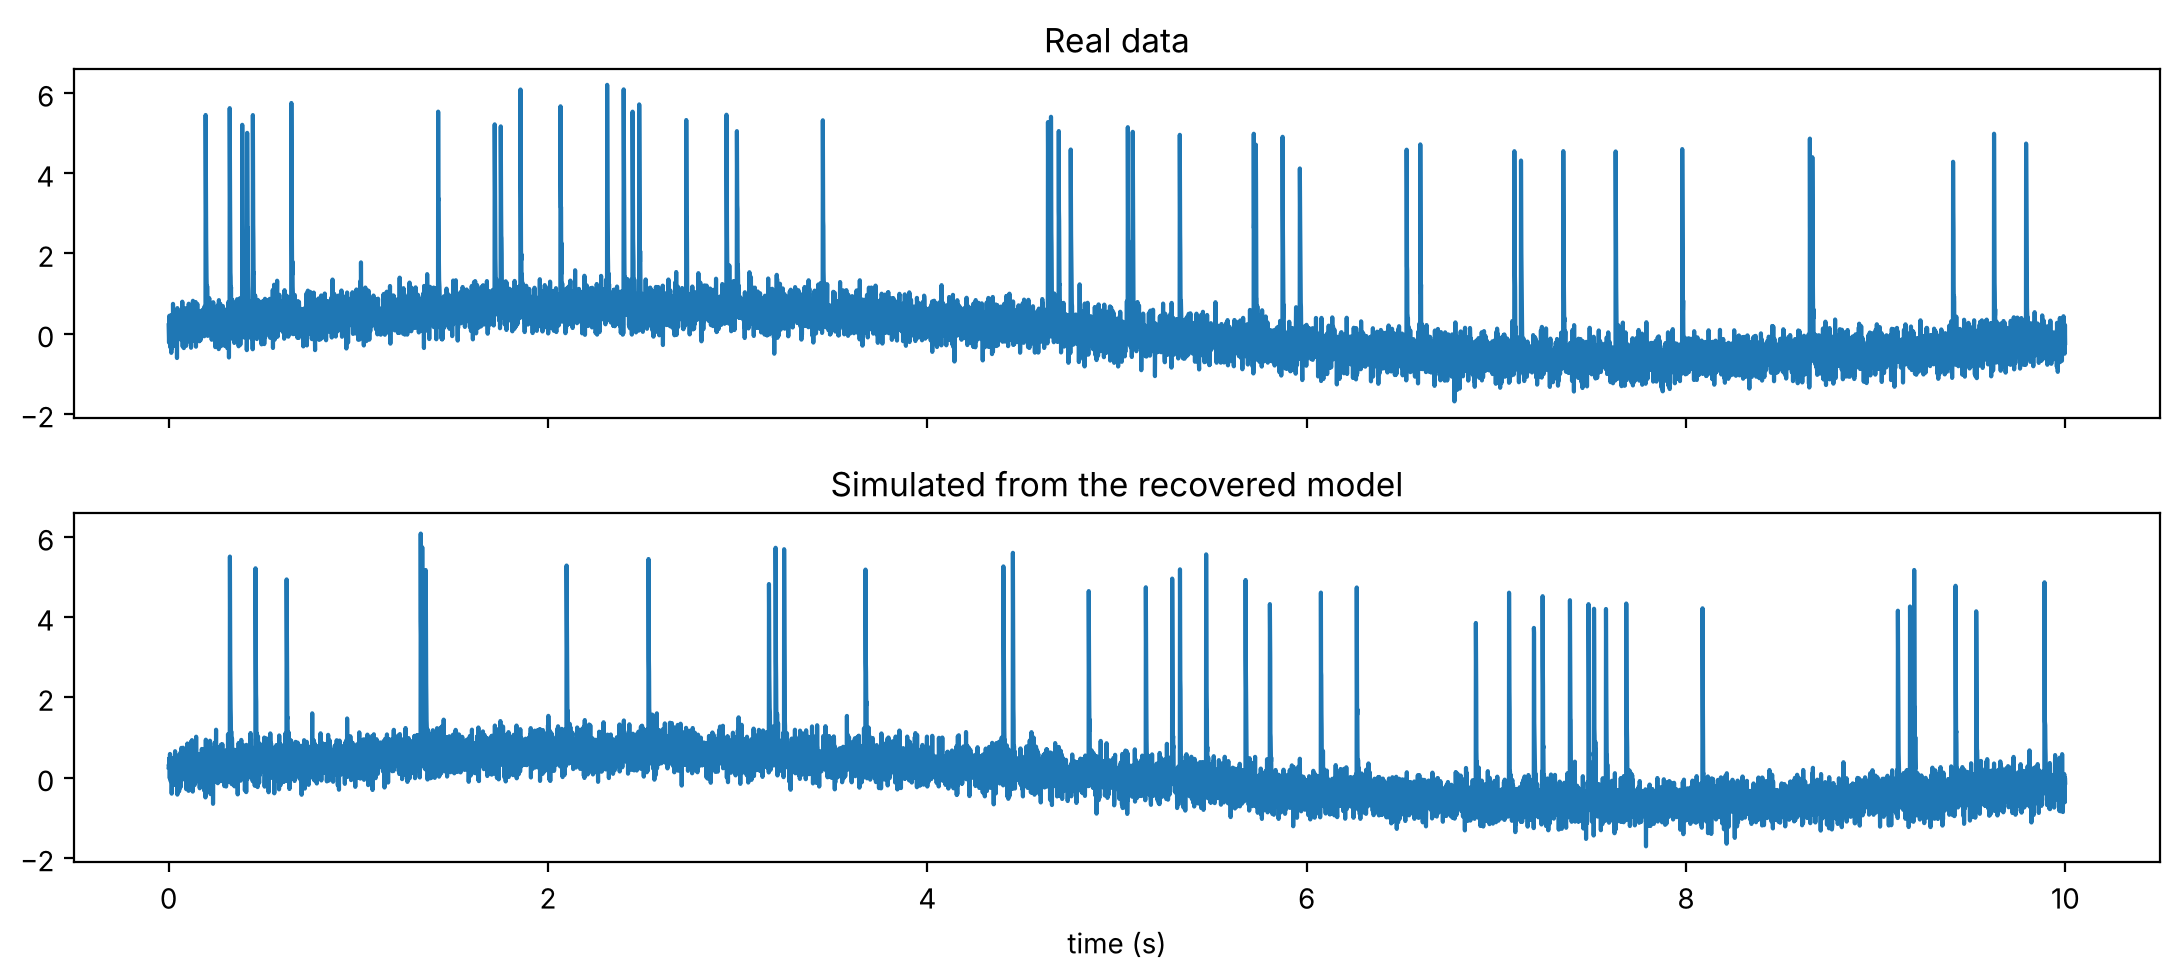

In [10]:
params = dict(D=p_hat[0], f=p_hat[1], phi=p_hat[2],
              A=p_hat[3], tau=p_hat[4], sigma=sigma_hat, rate=lam_hat)

def simulate(params, T=10.0, dt=0.001, seed=None):
    rng = np.random.default_rng(seed)
    tt = np.arange(0, T, dt)
    # 1) Poisson spike train: each 1 ms bin spikes with probability rate*dt
    onset_idx = np.flatnonzero(rng.random(len(tt)) < params["rate"] * dt)
    # 2) exponential spike waveform added at each onset
    v = np.zeros(len(tt))
    for s in onset_idx:
        v[s:] += params["A"] * np.exp(-(tt[s:] - tt[s]) / params["tau"])
    # 3) slow sinusoidal drift
    v += params["D"] * np.sin(2 * np.pi * params["f"] * tt + params["phi"])
    # 4) white Gaussian noise
    v += rng.normal(0, params["sigma"], len(tt))
    return tt, v, onset_idx

for k, v in params.items():
    print(f"{k:6s} = {v:.4g}")

t_sim, x_sim, _ = simulate(params, seed=1)
fig, ax = plt.subplots(2, 1, figsize=(11, 5), sharex=True, sharey=True)
ax[0].plot(t, x)
ax[0].set_title("Real data")
ax[1].plot(t_sim, x_sim)
ax[1].set_title("Simulated from the recovered model")
ax[1].set_xlabel("time (s)")
plt.tight_layout()
plt.show()

## 9. Validate: can the method recover parameters it knows?

A fitted model looking right is not proof. The stronger check is a **parameter recovery test**: generate 50 synthetic datasets from the model with known parameters, run the exact same detection and fitting pipeline on each, and see whether the true values come back. If they do, the pipeline is unbiased and the standard errors from step 5 are trustworthy.

In [11]:
rec = []
for seed in range(50):
    _, xs, true_on = simulate(params, seed=100 + seed)
    dxs = np.diff(xs, prepend=xs[0])
    on = np.flatnonzero(dxs > 2.5)
    p_s, _, r_s = fit(xs, on)
    rec.append([*p_s, r_s.std(), len(on) / 10.0, len(on) == len(true_on)])
rec = np.array(rec)
labels = ["D", "f", "phi", "A", "tau", "sigma", "rate"]
truth = [params[k] for k in labels]
print(f"{'param':6s} {'true':>9s} {'mean est':>9s} {'sd est':>8s}")
for i, k in enumerate(labels):
    print(f"{k:6s} {truth[i]:9.4f} {rec[:, i].mean():9.4f} {rec[:, i].std():8.4f}")
print(f"spike count detected exactly in {int(rec[:, -1].sum())}/50 simulations")

param       true  mean est   sd est
D         0.6466    0.6465   0.0049
f         0.0908    0.0908   0.0005
phi       0.2912    0.2921   0.0156
A         5.0177    5.0170   0.0382
tau       0.0030    0.0030   0.0000
sigma     0.2984    0.2975   0.0021
rate      4.2000    4.2420   0.7545
spike count detected exactly in 50/50 simulations


Every parameter is recovered without bias, the spread of the estimates matches the standard errors from step 5, and the detector finds the exact number of spikes in every run. The pipeline can be trusted on the real data.

## 11. Results file and testing module

Two companion files go with this notebook:

* `spike_model.py` fits the model to `spike_data.npz` and writes `simulated_spike_data.npz`, a new 10 s recording from the model with exactly the same structure as the original (keys `t` and `raw_data`, shape (10000,), float64, same time axis).
* `test_simulation.py` checks how close the simulation is to the original. It fits both files from scratch and runs 11 statistical tests covering the spikes, the drift and the noise, plus some descriptive similarity scores. Run `python test_simulation.py --plot comparison.png`, or `--calibrate 200` to check the tests themselves.